# M09 · Árbol de decisión

Modelo de árbol de la fase 2. Usamos el preprocesado y la evaluación comunes de `src/modeling.py`, para que todos los modelos se comparen igual.

**Reglas del equipo (EDA, paso 14.4):**
- Solo `train`. El test no se toca hasta M08.
- Validación cruzada con `StratifiedGroupKFold` agrupando por `grupo_producto`.
- Métrica principal: **F1 macro**, con recall por clase (sobre todo NOVA 2). Objetivo: gap train/CV < 0,05.
- Imputación dentro del pipeline, ajustada solo con el train de cada fold.
- Sin `log1p` ni escalado: los árboles cortan por umbrales, así que no les afecta la escala.
- Preprocesado y métricas con `build_preprocessor` y `evaluate_cv` de `src/modeling.py` (acuerdo del equipo), para que los números sean comparables con M01 y el resto por construcción.

**Experimentos:**
1. Árbol sin límite de profundidad (para ver el sobreajuste).
2. Barrido de `max_depth`.
3. Con `class_weight="balanced"`.
4. Con y sin `tiene_potenciadores`.

In [1]:
import sys
sys.path.insert(0, "..")

import json
import platform

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Funciones y constantes comunes del equipo
from src.modeling import (TARGET, GROUP, LABELS, load_train, get_feature_columns, build_preprocessor, evaluate_cv, MODELS_DIR, REPORTS_DIR)

In [2]:
df = load_train()
print(df.shape)
print(df[TARGET].value_counts(normalize=True).sort_index().round(3))

y, groups = df[TARGET], df[GROUP]

(38495, 35)
nova_group
1    0.129
2    0.112
3    0.204
4    0.555
Name: proportion, dtype: float64


## Función auxiliar

Un solo sitio para construir y evaluar cada variante. Guardamos los resultados en un diccionario para compararlos al final.

In [3]:
results = {}

def run(name, max_depth=None, class_weight=None, drop=()):
    cols = get_feature_columns(df, drop=drop)
    model = Pipeline([
        # Sin log ni escalado: solo imputación + one-hot de la categoría
        ("prep", build_preprocessor(cols, log_skewed=False, scale=False)),
        # Random_state fijo: si dos cortes empatan, el árbol elige siempre el mismo
        ("clf", DecisionTreeClassifier(max_depth=max_depth, class_weight=class_weight, random_state=42)),
    ])
    res = evaluate_cv(model, df[cols["all"]], y, groups)
    results[name] = res
    print(f"{name}: F1 train {res['f1_macro_train']}, F1 CV {res['f1_macro_cv']} "
              f"(±{res['f1_macro_cv_std']}), gap {res['gap']}, recall {res['recall']}")
    return res

## 0. Suelo: `DummyClassifier`

Un modelo que dice siempre la clase más frecuente (NOVA 4). Es la referencia que todos los modelos deben superar.

In [4]:
cols_all = get_feature_columns(df)
res = evaluate_cv(DummyClassifier(strategy="most_frequent"), df[cols_all["all"]], y, groups)
results["0 dummy (siempre NOVA 4)"] = res
print(f"0 dummy: F1 macro CV {res['f1_macro_cv']}, recall {res['recall']}")

0 dummy: F1 macro CV 0.1785, recall {'nova_1': 0.0, 'nova_2': 0.0, 'nova_3': 0.0, 'nova_4': 1.0}


**Resultado:** el dummy saca un F1 macro de 0,1785. Acierta todos los NOVA 4 (recall 1) y ninguno del resto (recall 0). Ese es el suelo: cualquier árbol que no lo supere de largo no sirve.

## 1. Árbol sin límite de profundidad

Sin `max_depth`, el árbol sigue dividiendo hasta que cada hoja es pura, así que puede memorizar el train. Esperamos un F1 en train casi perfecto y un gap grande.

In [5]:
run("1 sin límite", max_depth=None);

1 sin límite: F1 train 0.9997, F1 CV 0.941 (±0.0022), gap 0.0587, recall {'nova_1': 0.9402, 'nova_2': 0.9854, 'nova_3': 0.88, 'nova_4': 0.9581}


**Resultado:**

| | F1 train | F1 CV | Gap |
|---|---|---|---|
| Sin límite | 0,9997 | 0,941 (±0,0022) | **0,0587** |

El árbol sin límite acierta prácticamente todo el train, pero en validación baja casi 6 puntos. El gap (0,0587) supera el 5 % que pide el equipo: el árbol está **sobreajustando**. Sigue dividiendo hasta tener hojas puras, así que acaba memorizando productos concretos del train que luego no aparecen en los otros folds (la CV agrupa por `grupo_producto`, así que un producto y sus casi duplicados nunca están a la vez en train y validación).

Por eso hay que limitar `max_depth`.

## 2. Barrido de `max_depth`

Cuanto más profundo, más preguntas puede hacer el árbol: sube el F1 en train, pero a partir de cierto punto el CV deja de mejorar y el gap crece.

In [6]:
DEPTHS = [3, 4, 5, 6, 8, 10, 12, 15, 18, 20, 25]

for d in DEPTHS:
    run(f"2 depth={d}", max_depth=d)

2 depth=3: F1 train 0.7911, F1 CV 0.791 (±0.0064), gap 0.0, recall {'nova_1': 0.7007, 'nova_2': 0.8579, 'nova_3': 0.6783, 'nova_4': 0.8687}
2 depth=4: F1 train 0.8324, F1 CV 0.8323 (±0.0058), gap 0.0001, recall {'nova_1': 0.7005, 'nova_2': 0.9208, 'nova_3': 0.6783, 'nova_4': 0.9463}
2 depth=5: F1 train 0.8571, F1 CV 0.8548 (±0.0052), gap 0.0022, recall {'nova_1': 0.8417, 'nova_2': 0.9485, 'nova_3': 0.8586, 'nova_4': 0.859}
2 depth=6: F1 train 0.8936, F1 CV 0.8923 (±0.0045), gap 0.0013, recall {'nova_1': 0.9475, 'nova_2': 0.948, 'nova_3': 0.8479, 'nova_4': 0.8997}
2 depth=8: F1 train 0.9246, F1 CV 0.9213 (±0.0067), gap 0.0033, recall {'nova_1': 0.9792, 'nova_2': 0.9596, 'nova_3': 0.8617, 'nova_4': 0.9327}
2 depth=10: F1 train 0.9407, F1 CV 0.9335 (±0.0024), gap 0.0072, recall {'nova_1': 0.979, 'nova_2': 0.9652, 'nova_3': 0.8988, 'nova_4': 0.9377}
2 depth=12: F1 train 0.9521, F1 CV 0.9393 (±0.0012), gap 0.0128, recall {'nova_1': 0.9849, 'nova_2': 0.9775, 'nova_3': 0.8969, 'nova_4': 0.944

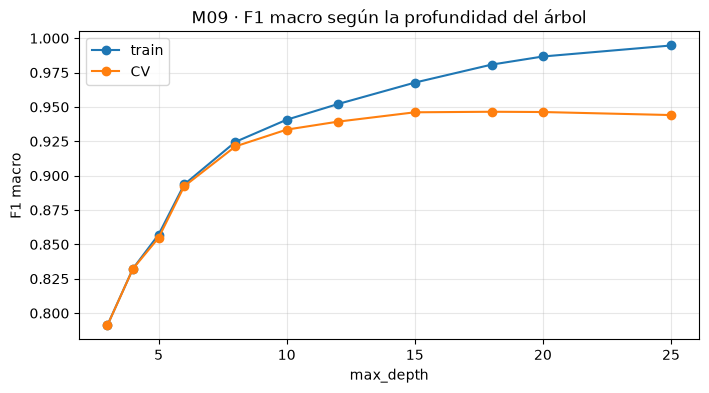

In [7]:
# Sacamos del diccionario los F1 de cada profundidad
f1_train = [results[f"2 depth={d}"]["f1_macro_train"] for d in DEPTHS]
f1_cv = [results[f"2 depth={d}"]["f1_macro_cv"] for d in DEPTHS]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(DEPTHS, f1_train, marker="o", label="train")
ax.plot(DEPTHS, f1_cv, marker="o", label="CV")
ax.set_xlabel("max_depth")
ax.set_ylabel("F1 macro")
ax.set_title("M09 · F1 macro según la profundidad del árbol")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Resultado:**

| max_depth | F1 train | F1 CV | Gap |
|---|---|---|---|
| 3 | 0,791 | 0,791 | 0,000 |
| 6 | 0,894 | 0,892 | 0,001 |
| 10 | 0,941 | 0,934 | 0,007 |
| 12 | 0,952 | 0,939 | 0,013 |
| 15 | 0,968 | 0,946 | 0,022 |
| 18 | 0,981 | 0,946 | 0,035 |
| 20 | 0,987 | 0,946 | 0,041 |
| 25 | 0,995 | 0,944 | **0,051** |

Cómo leer la curva:
- **Hasta una profundidad de 10**, train y CV suben juntos: cada nivel nuevo aprende reglas que sirven para productos que no ha visto.
- **A partir de 15**, el CV se queda plano en ~0,946 y el train sigue subiendo. Los niveles extra ya no aprenden reglas generales, solo memorizan.
- **Con una profundidad de 25** el gap ya supera el 5 %. El límite útil está entre 15 y 20.

## 3. Con `class_weight="balanced"`

Da más peso a las clases pequeñas (NOVA 4 es el 55 %). Lo probamos en las profundidades donde el F1 CV ya es alto.

In [8]:
for d in [8, 10, 12, 15, 18, 20]:
    run(f"3 balanced, depth={d}", max_depth=d, class_weight="balanced")

3 balanced, depth=8: F1 train 0.9153, F1 CV 0.9131 (±0.0053), gap 0.0022, recall {'nova_1': 0.997, 'nova_2': 0.9464, 'nova_3': 0.9113, 'nova_4': 0.8986}
3 balanced, depth=10: F1 train 0.9342, F1 CV 0.9286 (±0.0032), gap 0.0056, recall {'nova_1': 0.9842, 'nova_2': 0.9742, 'nova_3': 0.9338, 'nova_4': 0.9102}
3 balanced, depth=12: F1 train 0.9458, F1 CV 0.9379 (±0.0028), gap 0.008, recall {'nova_1': 0.9836, 'nova_2': 0.9831, 'nova_3': 0.9395, 'nova_4': 0.9213}
3 balanced, depth=15: F1 train 0.9571, F1 CV 0.9436 (±0.0027), gap 0.0134, recall {'nova_1': 0.9838, 'nova_2': 0.9842, 'nova_3': 0.9352, 'nova_4': 0.933}
3 balanced, depth=18: F1 train 0.9678, F1 CV 0.9482 (±0.0019), gap 0.0197, recall {'nova_1': 0.9798, 'nova_2': 0.9835, 'nova_3': 0.9353, 'nova_4': 0.9409}
3 balanced, depth=20: F1 train 0.9744, F1 CV 0.9496 (±0.0028), gap 0.0248, recall {'nova_1': 0.9756, 'nova_2': 0.9854, 'nova_3': 0.9278, 'nova_4': 0.947}


**Resultado:**

| max_depth | F1 train | F1 CV (balanced) | Gap (balanced) | F1 CV (sin peso) | Gap (sin peso) | Recall NOVA 3 (sin peso → balanced) | Recall NOVA 4 (sin peso → balanced) |
|---|---|---|---|---|---|---|---|
| 8 | 0,9153 | 0,9131 (±0,0053) | 0,0022 | 0,9213 | 0,0033 | 0,86 → 0,91 | 0,93 → 0,90 |
| 10 | 0,9342 | 0,9286 (±0,0032) | 0,0056 | 0,9335 | 0,0072 | 0,90 → 0,93 | 0,94 → 0,91 |
| 12 | 0,9458 | 0,9379 (±0,0028) | 0,0080 | 0,9393 | 0,0128 | 0,90 → 0,94 | 0,94 → 0,92 |
| 15 | 0,9571 | 0,9436 (±0,0027) | 0,0134 | 0,9461 | 0,0216 | 0,90 → 0,94 | 0,95 → 0,93 |
| 18 | 0,9678 | 0,9482 (±0,0019) | 0,0197 | 0,9465 | 0,0344 | 0,90 → 0,94 | 0,95 → 0,94 |
| 20 | 0,9744 | 0,9496 (±0,0028) | 0,0248 | 0,9463 | 0,0404 | 0,89 → 0,93 | 0,96 → 0,95 |

Qué vemos:
- **El gap es más pequeño con `balanced` en todas las profundidades.** Al pesar más las clases pequeñas, el árbol no dedica tantas divisiones a afinar NOVA 4, que es la mayoritaria. Por eso sobreajusta menos.
- **El recall de NOVA 3 sube entre 3 y 5 puntos**, y es la clase que más le cuesta al árbol. A cambio baja algo el de NOVA 4. Es el intercambio esperado: deja de favorecer a la clase grande.
- **NOVA 1 y NOVA 2 se quedan por encima de 0,97** a partir de una profundidad de 10, con y sin pesos.
- **En F1 CV, hasta 15 gana el árbol sin pesos. A partir de 18 gana `balanced`**: con poca profundidad, dar peso a las clases pequeñas obliga a sacrificar NOVA 4 sin tener ramas suficientes para compensarlo. Con más profundidad hay espacio para las dos cosas.
- Entre 18 y 20 con `balanced`, la diferencia de F1 CV (0,0014) es **menor que la std entre folds** (~0,002-0,003), así que en la práctica están empatadas.

## Elección de la referencia de M09

Aplicamos los criterios del equipo en orden:

1. **Gap < 0,05:** quedan fuera el árbol sin límite (0,0587) y el de profundidad 25 (0,051).
2. **Mejor F1 CV:** los mejores son `balanced` con profundidad 20 (0,9496), `balanced` con profundidad 18 (0,9482) y el árbol sin pesos con profundidad 15 (0,9461).
3. **Empates:** entre 20 y 18 con `balanced` la diferencia (0,0014) es menor que la std entre folds (~0,002-0,003), así que es un empate. Elegimos **18**, el más simple.
4. **Recall por clase:** frente al árbol sin pesos de profundidad 15, el `balanced` de profundidad 18 sube el recall de NOVA 3 de 0,90 a 0,94 con un gap parecido.

**Referencia de M09: `class_weight="balanced"`, `max_depth=18`** (F1 CV 0,9482 ± 0,0019, gap 0,0197).

## 4. Con y sin `tiene_potenciadores`

El EDA (paso 12) marcó esta variable como rara (2,8 % de los productos) y dejó la decisión para la fase 2. Comparamos la referencia con y sin ella.

In [9]:
REF = "3 balanced, depth=18"
REF_DEPTH, REF_CW = 18, "balanced"

run("4 balanced, depth=18, sin potenciadores",
    max_depth=REF_DEPTH, class_weight=REF_CW, drop=["tiene_potenciadores"]);

4 balanced, depth=18, sin potenciadores: F1 train 0.9671, F1 CV 0.9466 (±0.0024), gap 0.0206, recall {'nova_1': 0.9802, 'nova_2': 0.9842, 'nova_3': 0.933, 'nova_4': 0.9372}


**Resultado:**

| | F1 train | F1 CV | Gap | Recall NOVA 3 | Recall NOVA 4 |
|---|---|---|---|---|---|
| Con `tiene_potenciadores` (referencia) | 0,9678 | 0,9482 (±0,0019) | 0,0197 | 0,935 | 0,941 |
| Sin `tiene_potenciadores` | 0,9671 | 0,9466 (±0,0024) | 0,0206 | 0,933 | 0,937 |

Sin la variable, el F1 CV baja 0,0016, más o menos lo mismo que la std entre folds. El efecto es pequeño pero va en la misma dirección que en M01 (−0,002): el árbol la usa poco, pero algo aporta, sobre todo para distinguir NOVA 4. **La mantenemos**, que es lo acordado en el EDA, y así M01 y M09 usan las mismas variables.

## 5. Comparación de todas las variantes

Todas las variantes en una tabla, ordenadas por F1 CV. La referencia es `3 balanced, depth=18`.

In [10]:
# Una fila por variante, con las métricas del convenio del equipo
table = pd.DataFrame({
    name: {"F1 macro train": r["f1_macro_train"], "F1 macro CV": r["f1_macro_cv"],
           "std": r["f1_macro_cv_std"], "gap": r["gap"],
           **{f"recall {k}": v for k, v in r["recall"].items()}}
    for name, r in results.items()
}).T
table.sort_values("F1 macro CV", ascending=False)

,F1 macro train,F1 macro CV,std,gap,recall nova_1,recall nova_2,recall nova_3,recall nova_4
"3 balanced, depth=20",0.9744,0.9496,0.0028,0.0248,0.9756,0.9854,0.9278,0.9470
"3 balanced, depth=18",0.9678,0.9482,0.0019,0.0197,0.9798,0.9835,0.9353,0.9409
"4 balanced, depth=18, sin potenciadores",0.9671,0.9466,0.0024,0.0206,0.9802,0.9842,0.9330,0.9372
2 depth=18,0.9808,0.9465,0.0033,0.0344,0.9681,0.9851,0.8956,0.9542
2 depth=20,0.9867,0.9463,0.0038,0.0404,0.9626,0.9851,0.8938,0.9565
2 depth=15,0.9677,0.9461,0.0024,0.0216,0.9766,0.9828,0.9027,0.9517
2 depth=25,0.9947,0.9441,0.0021,0.0505,0.9600,0.9868,0.8795,0.9574
"3 balanced, depth=15",0.9571,0.9436,0.0027,0.0134,0.9838,0.9842,0.9352,0.9330
1 sin límite,0.9997,0.9410,0.0022,0.0587,0.9402,0.9854,0.8800,0.9581
2 depth=12,0.9521,0.9393,0.0012,0.0128,0.9849,0.9775,0.8969,0.9444


**Resultado:** la tabla resume lo visto en los pasos anteriores. Todas las variantes superan de largo al dummy (0,1785). Las que tienen mejor F1 CV están entre 0,946 y 0,950, separadas por menos de la std entre folds. Las únicas que incumplen el gap < 0,05 son el árbol sin límite y el de profundidad 25.

## 6. Matriz de confusión de la referencia

Filas = clase real, columnas = clase predicha. Son predicciones *out-of-fold*: cada producto lo predice un árbol que no lo vio al entrenar. La segunda tabla muestra lo mismo en % de cada fila (la diagonal es el recall).

In [11]:
cm = pd.DataFrame(results[REF]["confusion_matrix"],
                  index=[f"real {l}" for l in LABELS], columns=[f"pred {l}" for l in LABELS])
display(cm)

# Normalizada por filas: qué % de cada clase real acaba en cada predicción
display((cm.div(cm.sum(axis=1), axis=0) * 100).round(1))

,pred 1,pred 2,pred 3,pred 4
real 1,4852,19,61,20
real 2,36,4237,26,9
real 3,226,18,7356,265
real 4,214,16,1032,20108


,pred 1,pred 2,pred 3,pred 4
real 1,98.0,0.4,1.2,0.4
real 2,0.8,98.4,0.6,0.2
real 3,2.9,0.2,93.5,3.4
real 4,1.0,0.1,4.8,94.1


## 7. Análisis de errores

Recuperamos las predicciones out-of-fold de la referencia (mismos folds que `evaluate_cv`, porque el `random_state` es fijo) y comparamos los productos bien y mal clasificados en las variables más importantes.

In [12]:
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict

# Mismo modelo y mismos folds que la referencia
cols_ref = get_feature_columns(df)
ref_model = Pipeline([
    ("prep", build_preprocessor(cols_ref, log_skewed=False, scale=False)),
    ("clf", DecisionTreeClassifier(max_depth=REF_DEPTH, class_weight=REF_CW, random_state=42)),
])
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
errors = df.copy()
errors["pred"] = cross_val_predict(ref_model, df[cols_ref["all"]], y, groups=groups, cv=cv, n_jobs=-1)

# Media de algunas variables en cada combinación real → predicho
VARS = ["additives_n", "n_ingredientes", "tiene_aromas", "tiene_emulsionantes",
        "tiene_colorantes", "tiene_sal", "tiene_azucar", "tiene_aceite"]
PAIRS = [(4, 4), (4, 3), (3, 3), (3, 4), (1, 1), (3, 1), (4, 1)]

summary = pd.DataFrame({
    f"real {r} → pred {p}": errors[(errors[TARGET] == r) & (errors["pred"] == p)][VARS].mean()
    for r, p in PAIRS
}).T
summary.insert(0, "n", [((errors[TARGET] == r) & (errors["pred"] == p)).sum() for r, p in PAIRS])
summary.round(2)

,n,additives_n,n_ingredientes,tiene_aromas,tiene_emulsionantes,tiene_colorantes,tiene_sal,tiene_azucar,tiene_aceite
real 4 → pred 4,20108,3.34,11.47,0.65,0.50,0.22,0.57,0.58,0.39
real 4 → pred 3,1032,1.00,8.38,0.00,0.00,0.01,0.75,0.39,0.43
real 3 → pred 3,7356,0.44,5.15,0.00,0.00,0.00,0.81,0.23,0.40
real 3 → pred 4,265,0.90,8.87,0.00,0.01,0.00,0.49,0.55,0.49
real 1 → pred 1,4852,0.05,1.78,0.00,0.00,0.00,0.00,0.00,0.00
real 3 → pred 1,226,0.12,3.51,0.00,0.00,0.00,0.00,0.00,0.02
real 4 → pred 1,214,0.36,6.37,0.00,0.00,0.00,0.00,0.00,0.02


In [13]:
wrong_4_as_3 = errors[(errors[TARGET] == 4) & (errors["pred"] == 3)]
display(wrong_4_as_3["pnns_groups_2"].value_counts().head(6))
display(wrong_4_as_3[["product_name", "pnns_groups_2", "additives_n", "n_ingredientes"]]
        .sample(8, random_state=1))   # unos ejemplos para mirarlos a ojo

pnns_groups_2
unknown               178
Bread                 133
Cheese                 84
Milk and yogurt        70
Biscuits and cakes     66
Legumes                62
Name: count, dtype: int64

,product_name,pnns_groups_2,additives_n,n_ingredientes
11890,Veggieburger de tofu y espinacas,unknown,0.0,14.0
7905,Queso Fresco Batido 0 MG,Cheese,0.0,3.0
32201,Pan molde maíz y semillas,Bread,2.0,10.0
21732,Arroz integral,One-dish meals,0.0,18.0
34325,Garbanzos cocidos,Legumes,3.0,17.0
12343,Oat Muesli Strawberry,Breakfast cereals,0.0,9.0
21892,Cabecero de Lomo de bellota iberico,Processed meat,4.0,8.0
860,Alubias rojas,Legumes,2.0,5.0


**Resultado:**

| Real → predicho | n | Aditivos (media) | Nº ingredientes | % con aromas | % con emulsionantes |
|---|---|---|---|---|---|
| 4 → 4 (bien) | 20108 | 3,3 | 11,5 | 65 % | 50 % |
| **4 → 3 (error)** | **1032** | **1,0** | 8,4 | **0 %** | **0 %** |
| 3 → 3 (bien) | 7356 | 0,4 | 5,2 | 0 % | 0 % |
| 3 → 1 (error) | 226 | 0,1 | 3,5 | 0 % | 0 % |
| 4 → 1 (error) | 214 | 0,4 | 6,4 | 0 % | 0 % |

**El error principal es NOVA 4 → NOVA 3** (1032 productos, el 4,8 % de los NOVA 4):
- Estos productos **no tienen ninguno de los marcadores** que el árbol usa para reconocer NOVA 4: 0 % con aromas, 0 % con emulsionantes, casi ningún colorante, y solo 1 aditivo de media (frente a 3,3 en los NOVA 4 bien clasificados). Por las variables que tenemos, se parecen mucho más a un NOVA 3.
- Hipótesis (no comprobada en este notebook): OFF podría clasificarlos como NOVA 4 por algún ingrediente concreto que no está entre nuestras variables `tiene_*` (por ejemplo, ciertos aditivos o proteínas de leche). El árbol no puede ver lo que no le damos.
- Muchos no tienen categoría (`unknown`, 178), y el resto son sobre todo pan, queso, lácteos, galletas y legumbres: categorías donde la misma familia de productos tiene versiones NOVA 3 y NOVA 4. Sin categoría, el árbol pierde una de sus pistas.

**El segundo error es NOVA 3 → NOVA 4** (265 productos, el 3,4 % de los NOVA 3): el caso contrario, productos NOVA 3 con más ingredientes de lo normal (8,9 de media frente a 5,2), que el árbol confunde con ultraprocesados.

**Los errores hacia NOVA 1** (3 → 1: 226 y 4 → 1: 214) son productos con pocos ingredientes y sin sal, azúcar ni aceite. Con nuestras variables parecen alimentos sin procesar.

**NOVA 1 y NOVA 2 son las clases que mejor separa** (recall 0,98 en las dos): NOVA 1 por tener muy pocos ingredientes, y NOVA 2 (aceites, azúcar, sal, mantequilla) por su perfil de nutrientes tan característico.

**Comparación con M01:** según la matriz de confusión del notebook de M01 (variante 4a), la regresión logística comete los mismos tipos de error (4 → 3: 874, 3 → 1: 233, 4 → 1: 195). Por tanto, el límite no lo pone el modelo sino **la información que contienen las variables**. Para mejorar NOVA 3 vs 4 harían falta nuevas variables de ingredientes, no un modelo más complejo.

## 8. Entrenar la referencia con todo el train

Hasta ahora cada árbol se entrenaba con 4/5 del train (dentro de la CV). Para dibujarlo y guardarlo entrenamos la referencia (`balanced`, profundidad 18) con todo el train. Las métricas que reportamos siguen siendo las de la CV.

In [14]:
final = Pipeline([
    ("prep", build_preprocessor(cols_ref, log_skewed=False, scale=False)),
    ("clf", DecisionTreeClassifier(max_depth=REF_DEPTH, class_weight=REF_CW, random_state=42)),
])
final.fit(df[cols_ref["all"]], y)

tree = final.named_steps["clf"]   # el árbol, sin el preprocesado
# Nombres de las columnas tras el preprocesado, sin el prefijo "bin__", "num__"...
feature_names = [n.split("__", 1)[1] for n in final.named_steps["prep"].get_feature_names_out()]

print("Profundidad:", tree.get_depth(), "| Hojas:", tree.get_n_leaves())

Profundidad: 18 | Hojas: 545


## 9. Dibujo del árbol

Con 18 niveles y cientos de hojas, el árbol completo no se puede leer. Dibujamos sus **3 primeros niveles**, que son las divisiones que más productos separan. En cada nodo: la pregunta, el % de productos que llegan y la proporción de cada clase (ponderada por `class_weight="balanced"`). El color indica la clase mayoritaria.

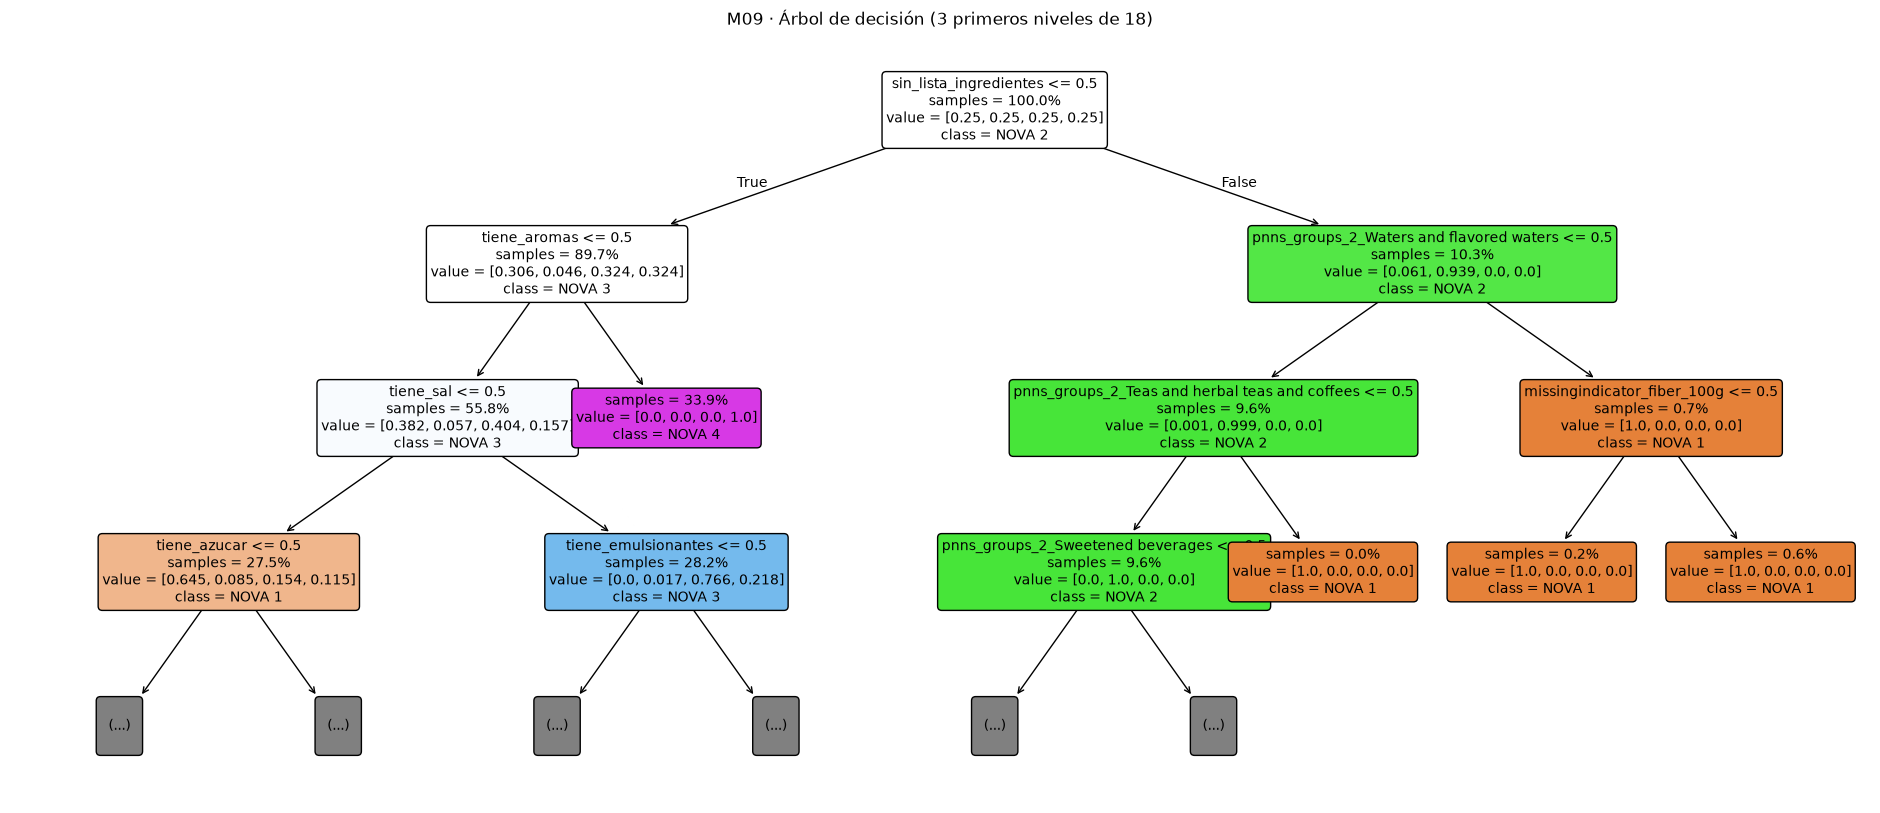

In [15]:
fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(tree, max_depth=3,                   # solo los 3 primeros niveles
          feature_names=feature_names,
          class_names=["NOVA 1", "NOVA 2", "NOVA 3", "NOVA 4"],
          filled=True, rounded=True,           # colores por clase y cajas redondeadas
          impurity=False, proportion=True,     # sin gini, valores en proporción
          fontsize=10, ax=ax)
ax.set_title("M09 · Árbol de decisión (3 primeros niveles de 18)")
fig.savefig(REPORTS_DIR / "m09_decision_tree_top.png", dpi=120, bbox_inches="tight")  # para el PR
plt.show()

In [16]:
from sklearn.tree import export_text

print(export_text(tree, feature_names=feature_names, max_depth=3,
                  class_names=["1", "2", "3", "4"]))

|--- sin_lista_ingredientes <= 0.50
|   |--- tiene_aromas <= 0.50
|   |   |--- tiene_sal <= 0.50
|   |   |   |--- tiene_azucar <= 0.50
|   |   |   |   |--- truncated branch of depth 15
|   |   |   |--- tiene_azucar >  0.50
|   |   |   |   |--- truncated branch of depth 15
|   |   |--- tiene_sal >  0.50
|   |   |   |--- tiene_emulsionantes <= 0.50
|   |   |   |   |--- truncated branch of depth 15
|   |   |   |--- tiene_emulsionantes >  0.50
|   |   |   |   |--- truncated branch of depth 4
|   |--- tiene_aromas >  0.50
|   |   |--- class: 4
|--- sin_lista_ingredientes >  0.50
|   |--- pnns_groups_2_Waters and flavored waters <= 0.50
|   |   |--- pnns_groups_2_Teas and herbal teas and coffees <= 0.50
|   |   |   |--- pnns_groups_2_Sweetened beverages <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- pnns_groups_2_Sweetened beverages >  0.50
|   |   |   |   |--- class: 1
|   |   |--- pnns_groups_2_Teas and herbal teas and coffees >  0.50
|   |   |   |--- class: 1
| 

**Resultado:** las primeras preguntas del árbol son muy fáciles de interpretar:

Cómo leerlo: las variables binarias valen 0 o 1, así que `tiene_aromas <= 0.50` significa "**no** tiene aromas" y `> 0.50` significa "**sí** tiene".

1. **¿Tiene lista de ingredientes?** (`sin_lista_ingredientes`). Es la primera división. Los productos sin lista son sobre todo aguas, infusiones y cafés, que el árbol separa enseguida por su categoría como NOVA 1.
2. **¿Tiene aromas?** (`tiene_aromas`). Si los tiene, el árbol dice **NOVA 4 directamente**, sin más preguntas. Los aromas son uno de los marcadores de ultraprocesado del sistema NOVA.
3. **¿Tiene sal?** y luego **¿tiene azúcar?** o **¿emulsionantes?**. Separan los productos sin procesar (NOVA 1) de los procesados (NOVA 3) y del resto de ultraprocesados.

El árbol ha aprendido por su cuenta una lógica muy parecida a la definición de NOVA: primero los marcadores de ultraprocesado, luego los ingredientes culinarios (sal, azúcar, aceite). Esto confirma lo que avisaba el EDA: OFF calcula NOVA con reglas basadas en ingredientes, y nuestras variables `tiene_*` las capturan bien.

Un detalle curioso: en la rama sin lista de ingredientes, las bebidas azucaradas también acaban en NOVA 1. No es lo que esperaríamos de una bebida azucarada, y puede venir de cómo asigna OFF el grupo NOVA cuando falta la lista de ingredientes. Lo dejamos anotado para revisarlo con el equipo.

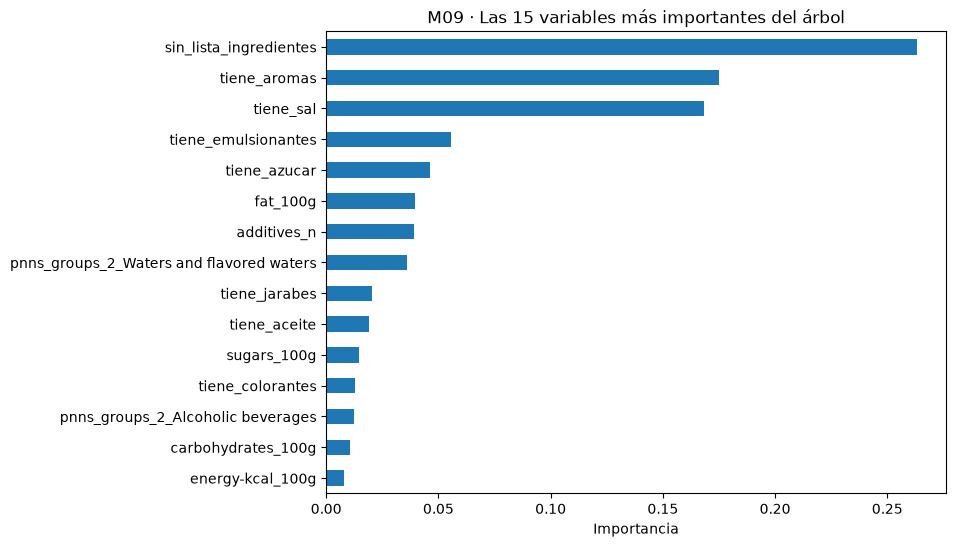

In [17]:
# Cuánto reduce la impureza cada variable en todo el árbol (suman 1)
importances = pd.Series(tree.feature_importances_, index=feature_names).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
importances.tail(15).plot.barh(ax=ax)      # las 15 más importantes
ax.set_xlabel("Importancia")
ax.set_title("M09 · Las 15 variables más importantes del árbol")
plt.show()

**Resultado:** tres variables binarias concentran más del 60 % de la importancia: `sin_lista_ingredientes` (~26 %), `tiene_aromas` (~18 %) y `tiene_sal` (~17 %). Les siguen `tiene_emulsionantes`, `tiene_azucar`, `fat_100g` y `additives_n`. Los nutrientes pesan bastante menos que los marcadores de ingredientes. `tiene_potenciadores` tiene una importancia de solo ~0,4 %, lo que cuadra con el pequeño efecto que vimos al quitarla.

## 10. Guardar el modelo y las métricas

Guardamos la referencia entrenada con todo el train (celda de la sección 8). El pipeline incluye el preprocesado, así que se puede usar directamente con un DataFrame con las columnas de `features`. Las métricas guardadas son las de la validación cruzada.

- Modelo: `models/m09_decision_tree.joblib` (la carpeta `models/` está en `.gitignore`: se regenera ejecutando este notebook).
- Métricas: `results/M09-metrics.json` (se sube al repo, con la misma estructura que M03 y M05).

In [18]:
from pathlib import Path

# Carpetas: models/ no se sube a git, results/ sí (misma convención que M03 y M05)
RESULTS_DIR = Path("../results")
MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
joblib.dump(final, MODELS_DIR / "m09_decision_tree.joblib")   # pipeline completo

metrics = {
    "model": "DecisionTreeClassifier",
    "variant": REF,
    "params": {"max_depth": REF_DEPTH, "class_weight": REF_CW, "log_skewed": False,
               "scale": False, "dropped": [], "random_state": 42},   # "params", igual que M03 y M05
    "features": cols_ref["all"],
    "cv": results[REF],                                  # métricas de la CV, no del modelo final
    "dummy_cv": results["0 dummy (siempre NOVA 4)"],
    "tree": {"depth": int(tree.get_depth()), "n_leaves": int(tree.get_n_leaves())},
    "n_train": len(df),
    "env": {"python": platform.python_version(), "scikit-learn": sklearn.__version__},
}
with open(RESULTS_DIR / "M09-metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print("Guardado: models/m09_decision_tree.joblib y results/M09-metrics.json")

Guardado: models/m09_decision_tree.joblib y results/M09-metrics.json


## Conclusiones

- **Suelo:** el dummy (siempre NOVA 4) tiene un F1 macro de 0,1785. Todas las variantes del árbol lo superan de largo.
- **Sin límite, el árbol sobreajusta:** F1 de 0,9997 en train frente a 0,9410 en CV (gap 0,0587 > 0,05). Limitar `max_depth` es necesario.
- **Referencia de M09: `class_weight="balanced"`, `max_depth=18`.** F1 macro CV 0,9482 (±0,0019), gap 0,0197. Recall: NOVA 1 0,980, NOVA 2 0,984, NOVA 3 0,935, NOVA 4 0,941. A partir de 15 niveles el F1 CV ya no mejora y solo crece el gap. `balanced` reduce el gap y sube el recall de NOVA 3 unos 4 puntos.
- **`tiene_potenciadores` se mantiene:** sin ella el F1 CV baja de 0,9482 a 0,9466, en línea con M01.
- **Errores:** casi todos entre NOVA 3 y NOVA 4. El 4,8 % de los NOVA 4 se predicen como NOVA 3: son productos sin ninguno de los marcadores de ultraprocesado que tenemos como variables, a veces con datos engañosos en OFF. M01 comete los mismos tipos de error (ver su matriz de confusión), así que el límite está en las variables y no en el modelo.
- **Interpretabilidad:** las primeras divisiones del árbol (lista de ingredientes, aromas, sal, azúcar, emulsionantes) reproducen la lógica de NOVA. Tres variables binarias suman más del 60 % de la importancia.
- **Comparación con M01:** la regresión logística saca un F1 CV algo mayor (0,9508 frente a 0,9482, una diferencia del orden de la std) y un gap menor (0,0014 frente a 0,0197). El árbol no la mejora en números, pero sus reglas se pueden leer y explicar.
- **El test no se ha usado.** La comparación final entre modelos se hará en M08.